# 199. Binary Tree Right Side View
**Difficulty:** 🟡 Medium · **Topic:** Trees · **Pattern:** [BFS Level Order](README.md) · **LeetCode:** https://leetcode.com/problems/binary-tree-right-side-view/

## 💡 Concepts

**Core concept(s):** **BFS level order** — process the tree one level at a time and keep only the **last node of each level**.

**Why it applies here:**
- Standing on the right, you see exactly one node per level: the rightmost one.
- "One answer per level" is the shape a level-by-level queue walk produces naturally.

**Key intuition:**
- Drain the queue one level at a time, left to right.
- The node you pop last in that level is the one visible from the right.
- The rightmost node is *not* always on the right spine: if the right subtree is shorter, a node from the left subtree shows through at the deeper levels.

---

### 📚 What is a Binary Tree?
- A **binary tree** is a set of nodes in a branching shape.
- Each node holds a value and up to two children: **left** and **right**.
- The top node is the **root**; nodes with no children are **leaves**.
- The **depth** of a node is how many edges it is below the root; the **height** `h` of the tree is the largest depth + 1.
- **In Python:** a small `TreeNode` class with `.val`, `.left`, `.right`.

### 📚 What is BFS (Breadth-First Search) / a Queue?
- A **queue** is a first-in, first-out line: you add at the back and take from the front.
- **BFS** explores a tree level by level: take a node from the front, push its children to the back, repeat.
- Because children always join the back, every node of level `d` leaves the queue before any node of level `d + 1`.
- **Level snapshot:** at the start of a level, `len(q)` is exactly the number of nodes on that level, so `for _ in range(len(q))` drains one level and nothing more.
- **Complexity:** each node is pushed and popped once → **O(n)** time; the queue holds at most one level plus part of the next → **O(w)** space, where `w` is the widest level.
- **In Python:** `collections.deque` — `append` adds to the back, `popleft` takes from the front, both O(1). (A plain `list.pop(0)` is O(n).)

### 📚 What is DFS (Depth-First Search) / a Stack?
- **DFS** dives down one branch as far as it can before backing up to try the next branch.
- It can be driven by a **stack** (last-in, first-out): pop a node, push its children, repeat. Whatever is pushed last is explored first.
- **Complexity:** each node is visited once → **O(n)** time; the stack holds about one path plus pending siblings → **O(h)** space.
- **In Python:** a plain `list` with `append` / `pop` (both O(1) at the end).

---

**Prerequisite knowledge:**
- Building a tree from a LeetCode-style level-order list.
- The level-order traversal template (see [Binary Tree Level Order Traversal](binary_tree_level_order_traversal.ipynb)).

## 📝 Problem

Imagine standing on the **right side** of a binary tree. Return the values of the nodes you can see, ordered **top to bottom**.

**Example 1**
```
root = [1,2,3,None,5,None,4]  ->  [1, 3, 4]

        1        <- see 1
       / \
      2   3      <- see 3
       \   \
        5   4    <- see 4 (5 is hidden behind 4)
```

**Example 2** — the left subtree shows through
```
root = [1,2,3,4,None,None,None,5]  ->  [1, 3, 4, 5]

          1      <- see 1
         / \
        2   3    <- see 3
       /
      4          <- see 4 (nothing on the right at this depth)
     /
    5            <- see 5
```

**Constraints:** `0 <= number of nodes <= 100`, `-100 <= Node.val <= 100`.

> Three approaches: a brute-force rescan per depth (`O(n·h)`), then two `O(n)` ones — DFS right-first and the BFS level-order template.

In [1]:
from typing import Optional, List
from collections import deque

class TreeNode:
    """A single node of a binary tree: a value plus links to up to two children."""
    def __init__(self, val=0, left=None, right=None):
        self.val = val                     # the number stored at this node
        self.left = left                   # the left child (or None)
        self.right = right                 # the right child (or None)

def build_tree(values):
    """Build a tree from a level-order list, LeetCode style (None = missing child)."""
    if not values or values[0] is None:
        return None
    root = TreeNode(values[0]); q = deque([root]); i = 1
    while q and i < len(values):
        node = q.popleft()                 # the parent we're attaching children to
        if i < len(values):                # attach the left child (if present)
            if values[i] is not None:
                node.left = TreeNode(values[i]); q.append(node.left)
            i += 1
        if i < len(values):                # attach the right child (if present)
            if values[i] is not None:
                node.right = TreeNode(values[i]); q.append(node.right)
            i += 1
    return root

def build_left_chain(n):
    """A degenerate tree 1 -> 2 -> ... -> n where every node is a LEFT child (height n).
    Built iteratively so large n never hits Python's recursion limit. Used by the benchmark."""
    root = TreeNode(1); cur = root
    for v in range(2, n + 1):
        cur.left = TreeNode(v); cur = cur.left
    return root

### Approach 1 — Brute Force: rescan the tree for every depth

**Idea:**
1. For depth `0, 1, 2, ...`, walk the tree from the root again, left before right.
2. Stop descending once you reach the target depth; every node met at that depth overwrites `last`, so the final value is the rightmost one.
3. When a depth has no nodes at all, the tree is exhausted — stop.

**Time complexity:** `O(n·h)` — the scan for depth `d` revisits every node above it; summed over `h` depths that is up to `n·h` visits (`O(n²)` on a chain-shaped tree).

**Space complexity:** `O(h)` — the explicit stack holds one root-to-node path plus pending siblings (output aside).

In [2]:
def right_side_view_brute(root: Optional[TreeNode]) -> List[int]:
    res = []
    depth = 0
    while True:
        last = None                                # rightmost value seen at `depth` so far
        stack = [(root, 0)] if root else []
        while stack:
            node, d = stack.pop()
            if d == depth:
                last = node.val                    # visited left-to-right, so later = further right
                continue                           # nothing below this depth matters for this pass
            if node.right: stack.append((node.right, d + 1))   # push right first...
            if node.left:  stack.append((node.left, d + 1))    # ...so left is popped first
        if last is None:                           # no node at this depth: tree exhausted
            return res
        res.append(last)
        depth += 1                                 # next pass rescans from the root

### Approach 2 — DFS, right child first

**Idea:**
- Walk the tree depth-first but always explore the **right** child before the left.
- The first node you ever reach at a new depth is therefore the rightmost node of that depth.
- Track it with one check: `if depth == len(res)` — "this depth has no answer yet" — then append.

**Time complexity:** `O(n)` — every node is pushed and popped once.

**Space complexity:** `O(h)` — the stack holds roughly one path plus one pending sibling per level.

In [3]:
def right_side_view_dfs(root: Optional[TreeNode]) -> List[int]:
    res = []
    stack = [(root, 0)] if root else []
    while stack:
        node, depth = stack.pop()
        if depth == len(res):              # first node reached at this depth...
            res.append(node.val)           # ...is the rightmost one, because right is explored first
        if node.left:  stack.append((node.left, depth + 1))    # push left first...
        if node.right: stack.append((node.right, depth + 1))   # ...so right is popped first
    return res

### Approach 3 — BFS Level Order, keep the last node (optimal · pattern template)

**Idea:** the [BFS Level Order](README.md) template, unchanged except for what each level records.
1. Put the root in a queue.
2. While the queue is not empty, drain **exactly one level**: `for _ in range(len(q))` pops every node of the current level, left to right, and pushes their children.
3. When that inner loop ends, `node` is the last node popped — the rightmost node of the level. Append its value.

**Time complexity:** `O(n)` — each node enters and leaves the queue once.

**Space complexity:** `O(w)` — the queue holds at most one level plus part of the next (`w` = widest level, up to about `n/2` in a full tree).

> Same `O(n)` time as Approach 2. BFS is the interview target here because it is the level-order template reused as is, it is iterative, and it reads directly as "last node per level".

In [4]:
def right_side_view_bfs(root: Optional[TreeNode]) -> List[int]:
    res = []
    if not root:
        return res
    q = deque([root])
    while q:
        for _ in range(len(q)):            # snapshot: current queue = exactly one level
            node = q.popleft()
            if node.left:  q.append(node.left)    # children wait in the queue for the next level
            if node.right: q.append(node.right)
        res.append(node.val)               # `node` is the last one popped = rightmost on this level
    return res

In [5]:
# Correctness check
import random

tests = [
    ([1, 2, 3, None, 5, None, 4],          [1, 3, 4]),     # LeetCode example 1
    ([1, 2, 3, 4, None, None, None, 5],    [1, 3, 4, 5]),  # LeetCode example 2: left subtree shows through
    ([1, None, 3],                         [1, 3]),        # LeetCode example 3
    ([],                                   []),            # empty tree
    ([7],                                  [7]),           # single node
    ([1, 2, None, 3, None, 4],             [1, 2, 3, 4]),  # left-only chain: every node is visible
]
for vals, exp in tests:
    root = build_tree(vals)
    a, b, c = right_side_view_brute(root), right_side_view_dfs(root), right_side_view_bfs(root)
    print(f"{str(vals):36} -> {c}")
    assert a == b == c == exp, f"mismatch on {vals}: brute={a} dfs={b} bfs={c}"

# Randomised cross-check: all three approaches must agree on many random tree shapes
rng = random.Random(199)
for _ in range(300):
    vals = [rng.randint(-100, 100) if rng.random() < 0.75 else None for _ in range(rng.randint(0, 40))]
    root = build_tree(vals)
    assert right_side_view_brute(root) == right_side_view_dfs(root) == right_side_view_bfs(root), vals
print("300 random trees: all three approaches agree")

print("\nAll tests passed")

[1, 2, 3, None, 5, None, 4]          -> [1, 3, 4]
[1, 2, 3, 4, None, None, None, 5]    -> [1, 3, 4, 5]
[1, None, 3]                         -> [1, 3]
[]                                   -> []
[7]                                  -> [7]
[1, 2, None, 3, None, 4]             -> [1, 2, 3, 4]
300 random trees: all three approaches agree

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured**. We time each approach on trees of growing size `n` and read the **doubling ratio** — how much runtime grows when `n` doubles.

| Theoretical | Ratio when `n` → `2n` |
|-------------|-----------------------|
| `O(log n)`    | ≈ **1×** |
| `O(n)`        | ≈ **2×** |
| `O(n²)`       | ≈ **4×** |

The worst case for the brute force is a **chain** (every node a left child): height `h = n`, so its `O(n·h)` becomes `O(n²)` and should show ≈4×, while DFS and BFS stay ≈2×. All three approaches are iterative, so a deep chain is safe.


brute O(n*h)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
      500 |       5.38 |           n/a
     1000 |      22.99 |         4.27x
     2000 |      92.66 |         4.03x


     4000 |     387.61 |         4.18x

dfs O(n)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
      500 |       0.04 |           n/a
     1000 |       0.07 |         1.64x
     2000 |       0.16 |         2.32x
     4000 |       0.29 |         1.78x

bfs O(n)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
      500 |       0.05 |           n/a
     1000 |       0.07 |         1.62x
     2000 |       0.20 |         2.69x
     4000 |       0.34 |         1.74x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


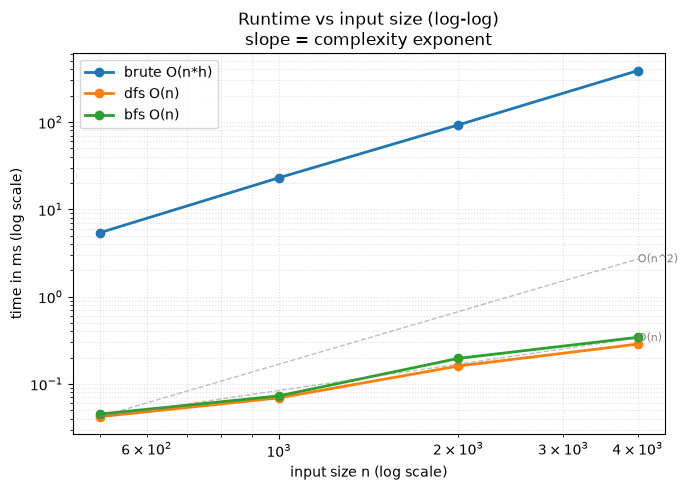

{'brute O(n*h)': [5.384583026170731,
  22.991874953731894,
  92.65787503682077,
  387.6065829535946],
 'dfs O(n)': [0.04208402242511511,
  0.06920797750353813,
  0.16029097605496645,
  0.2858750522136688],
 'bfs O(n)': [0.04508392885327339,
  0.07299997378140688,
  0.1961250090971589,
  0.3418329870328307]}

In [6]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark

def make_worst_case(n):
    return (build_left_chain(n),)      # height n: the brute force's worst shape
solutions = {
    "brute O(n*h)": right_side_view_brute,
    "dfs O(n)": right_side_view_dfs,
    "bfs O(n)": right_side_view_bfs,
}
sizes = [500, 1000, 2000, 4000]

benchmark(solutions, make_worst_case, sizes, plot=True)

## 🧩 Patterns Learned

- **Pattern:** [BFS Level Order](README.md) — the level-order template unchanged; instead of saving the whole level, save only the last node popped in each `for _ in range(len(q))` pass.
- **"One answer per level" → snapshot the queue size:** freezing `len(q)` at the start of a level separates it cleanly from the next; then pick what to keep (last node, first node, max, average, the full list).
- **DFS alternative — "first visit at a new depth":** with right-before-left order, `depth == len(res)` marks the first (rightmost) node of each depth. Same `O(n)` time, `O(h)` space.
- **Signal:** "visible from the right/left side", "rightmost/leftmost node of each level", "per level", "by depth".
- **Related problems:** Binary Tree Level Order Traversal, Binary Tree Zigzag Level Order Traversal, Average of Levels in Binary Tree, Find Bottom Left Tree Value.
- **Common pitfalls:**
  1. Returning only the right spine (`root.right.right...`) — it misses nodes from a deeper left subtree (Example 2).
  2. Reading `len(q)` *inside* the level loop after children were appended — the level boundary is lost.
  3. In the DFS version, visiting left before right — then the first node per depth is the *leftmost*.
  4. Forgetting the empty tree.